# Kaisla Miettinen

Opiskelijanumero: 2523617

### Tehtyjen tehtävien merkinnät

0. tehty
1. tehty
3. tehty
4. tehty
5. tehty
6. tehty
7. tehty


In [1]:
import numpy as np
import matplotlib.pyplot as plt

0. Lue tiedostossa t7kuva.JPG oleva kuva. Tulosta kuvan muoto (shape) ja kuvataulukon elementtien määrä.

In [2]:
# 0. Luetaan kuva ja tarkastellaan sen kokoa
kuva = plt.imread("t7kuva.jpg")

print("Kuvan muoto (height, width, channels):", kuva.shape)
print("Kuvataulukon elementtien määrä:", kuva.size)


Kuvan muoto (height, width, channels): (3000, 3000, 3)
Kuvataulukon elementtien määrä: 27000000


1 (3p). Muodosta kuvan jokaisesta kanavasta (syvyyssuuntaiset koordinaatit 0, 1 ja 2 histogrammi). Vihje: poimi kanava käyttäen slicing-mekanismia ja muuta se yksiulotteiseksi (käyttämällä esim. reshape()-komentoa). Kuvan y-akselin skaalan voi määritellä set_ylim -komennolla. Esimerkkikuvat on tehty käyttäen plt.subplots -komentoa mutta voit tehdä ne myös normaaliin tapaan.

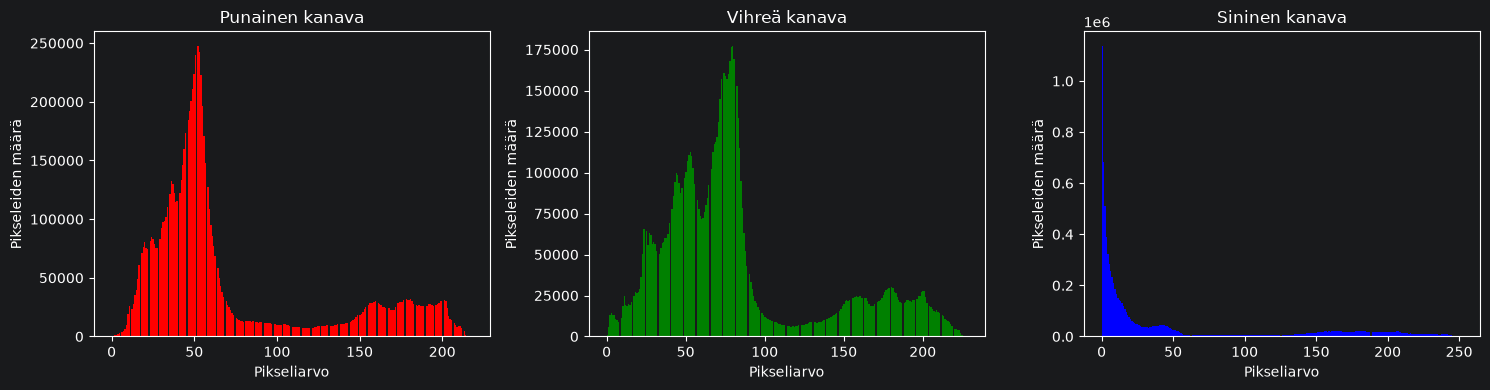

In [3]:
# 1. Muodostetaan histogrammit kuvan RGB-kanavista
fig, akselit = plt.subplots(1, 3, figsize=(15, 4))

kanavien_nimet = ["Punainen", "Vihreä", "Sininen"]
kanavien_varit = ["red", "green", "blue"]

for i in range(3):
    kanava = kuva[:, :, i].reshape(-1)
    akselit[i].hist(kanava, bins=256, color=kanavien_varit[i])
    akselit[i].set_title(kanavien_nimet[i] + " kanava")
    akselit[i].set_xlabel("Pikseliarvo")
    akselit[i].set_ylabel("Pikseleiden määrä")

plt.tight_layout()
plt.show()


3 (1p). Seuraavia vaiheita varten skaalaa kuva siten, että pikseliarvot ovat välillä 0...1. Näytä kuva sekä sellaisenaan että negatiivina (pikseliarvo 0 muuttuu arvoksi 1, arvo 1 arvoksi 0, 0.5 arvoksi 0.5 jne).

In [4]:
# 3. Skaalataan pikseliarvot välille 0...1
kuva_01 = kuva.astype(float) / 255.0


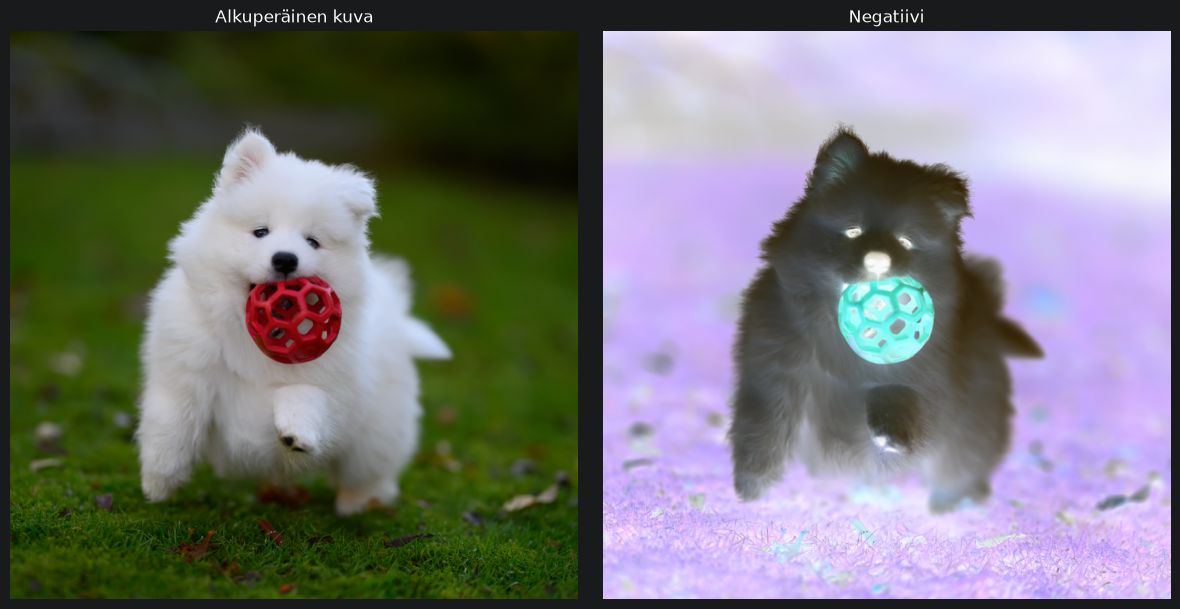

In [5]:
# Näytetään alkuperäinen kuva ja sen negatiivi
negatiivi = 1 - kuva_01

fig, akselit = plt.subplots(1, 2, figsize=(12, 6))

akselit[0].imshow(kuva_01)
akselit[0].set_title("Alkuperäinen kuva")
akselit[0].axis("off")

akselit[1].imshow(negatiivi)
akselit[1].set_title("Negatiivi")
akselit[1].axis("off")

plt.tight_layout()
plt.show()


4 (2p). Tee kuvasta lämpimämpisävyinen lisäämällä punaista ja vähentämällä sinistä (kasvata punaisen kanavan arvoja, pienennä sinisen). Kokeile eri menetelmiä (esim. kertolasku, jakaminen, lisääminen, vähentäminen) kunnes saat tuloksen johon olet tyytyväinen. Muista varmistaa, että mikään pikseliarvo ei ylitä arvoa 1 (käytä esim. npminimum -komentoa).

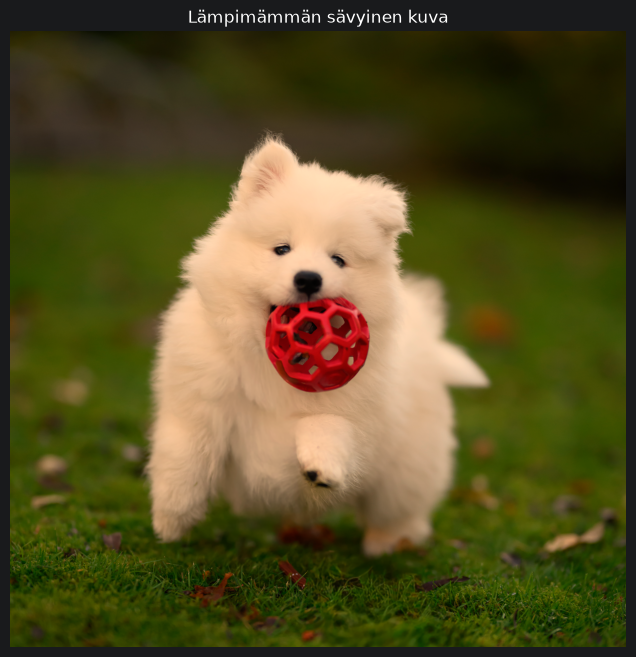

In [6]:
# 4. Muutetaan kuva lämpimämmän sävyiseksi
lampima = kuva_01.copy()

# Lisätään punaista ja vähennetään sinistä
lampima[:, :, 0] = np.minimum(lampima[:, :, 0] * 1.25, 1)
lampima[:, :, 2] = lampima[:, :, 2] * 0.75

plt.figure(figsize=(8, 8))
plt.imshow(lampima)
plt.title("Lämpimämmän sävyinen kuva")
plt.axis("off")
plt.show()


5 (1p). Rajaa kuva siten, että koiranpentu täyttää lähes koko kuvan. Vihje: käytä taas slicing-mekanismia. Näytä kuva.

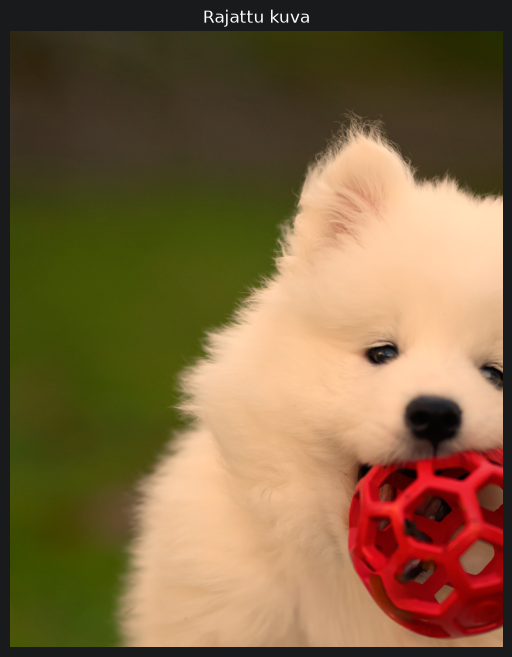

Rajatun kuvan muoto: (1500, 1200, 3)


In [7]:
# 5. Rajataan kuva niin, että koiranpentu täyttää lähes koko kuvan
rajattu_kuva = lampima[280:1780, 420:1620, :]

plt.figure(figsize=(7, 8))
plt.imshow(rajattu_kuva)
plt.title("Rajattu kuva")
plt.axis("off")
plt.show()

print("Rajatun kuvan muoto:", rajattu_kuva.shape)


6 (3p). Monista rajattua kuvaa siten, että saat ison kuvan (noin kokoa 12000x9000 pikseliä). Näytä kuva ja tulosta sen dimensiot. Vihje käytä concatenate() -funktiota kuvien liimaamiseen yhteen. Saatat haluta ensin muodostaa yhden rivin ja sen jälkeen koko kuvan liittämällä rivejä peräkkäin. Muista tässä axis -määreet, joilla määrittelet mihin suuntaan liittäminen tehdään.

Ison kuvan muoto: (9000, 12000, 3)
Ison kuvan leveys: 12000
Ison kuvan korkeus: 9000


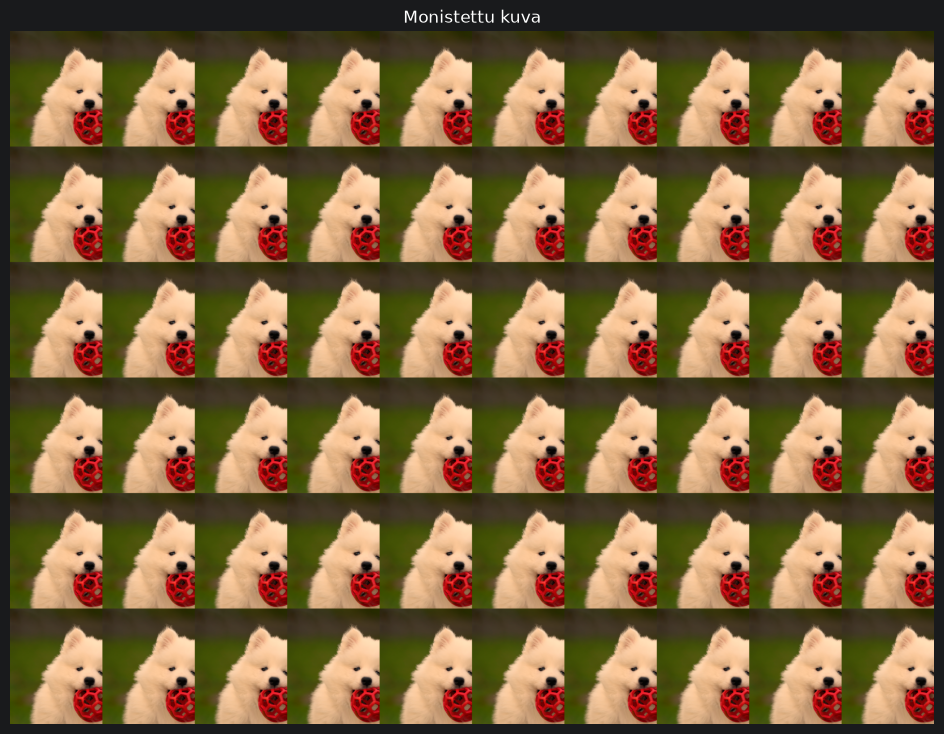

In [8]:
# 6. Monistetaan rajattua kuvaa kokoon 12000 x 9000 pikseliä

# Muutetaan kuva uint8-muotoon, jotta suuri taulukko vie vähemmän muistia.
rajattu_uint8 = (rajattu_kuva * 255).clip(0, 255).astype(np.uint8)

# Yhdelle riville 10 kuvaa vierekkäin: leveys 12000 pikseliä.
kuvarivi = np.concatenate([rajattu_uint8] * 10, axis=1)

# Yhdistetään 6 riviä päällekkäin: korkeus 9000 pikseliä.
isokuva = np.concatenate([kuvarivi] * 6, axis=0)

print("Ison kuvan muoto:", isokuva.shape)
print("Ison kuvan leveys:", isokuva.shape[1])
print("Ison kuvan korkeus:", isokuva.shape[0])

plt.figure(figsize=(12, 9))
plt.imshow(isokuva)
plt.title("Monistettu kuva")
plt.axis("off")
plt.show()


7. Tallenna kuva jpg-muodossa ja nyt voit käyttää sitä tietokoneesi taustakuvana!

In [9]:
# 7. Tallennetaan iso kuva JPG-muodossa
plt.imsave("isokuva.jpg", isokuva)
print("Kuva tallennettu tiedostoon isokuva.jpg")


Kuva tallennettu tiedostoon isokuva.jpg
